In [4]:
from rdkit import Chem
import pickle
import os
import json
import numpy as np
import xgboost
import sys
from shared.ml_helper import make_fingerprint # pyright: ignore[reportMissingImports]
from matplotlib import pyplot as plt
from cycler import cycler

from matplotlib.colors import ListedColormap
import numpy as np


In [5]:
# Data analysis



arrow_types = {
    0: "atom to atom",
    1: "atom to bond",
    2: "bond to atom",
    3: "bond to bond",
    4: "atom to H+",
    5: "bond to H+",
    6: "H- to atom",
    7: "H- to bond",
    8: '-H+ to bond',
    9: '-H+ to atom',
    10: 'elimination to bond'
}


training_dir = "training_sets/20260202"

with open('bitvector_origins.txt', 'w') as origin_file:
    pass #

# Get list of subdirectories and sort them numerically
subdirs = [d for d in os.listdir(training_dir) if os.path.isdir(os.path.join(training_dir, d))]
subdirs = sorted(subdirs, key=lambda x: int(x))  # Sort by integer folder name

bitvectors = []
outcomes = []
contributors = {}
count_dirs = 0
count_arrows = 0

for subdir in subdirs:
    count_dirs += 1
    folder_path = os.path.join(training_dir, subdir)
    json_path = os.path.join(folder_path, 'data.json')
    pkl_path = os.path.join(folder_path, 'sm.pkl')
    with open(pkl_path, "rb") as f:
        try:
            sm = pickle.load(f)
        except Exception as e:
                    print(f"Error processing {pkl_path}: {e}")
    with open(json_path, 'r') as file:
        data = json.load(file)
    choices = data['choices']
    contributor = data.get('contributor')
    if contributor in contributors:
        if contributor == '':
             contributors[None] += 1
        else:
            contributors[contributor] += 1
    else:
        if contributor == '':
             contributors[None] = 1
        else:
            contributors[contributor] = 1
    for id, info in choices.items():
        # bitvector for the mechanism
        if info['probable'] is None:
            continue
        try:
            sum_finger_print = make_fingerprint(sm, info['mechanism'])
        except:
             print(f"Error processing {training_dir}/{subdir} mechanism {info['mechanism']}")
        bitvectors.append(sum_finger_print)
        
        count_arrows += 1
        outcomes.append(info['probable'])
        # Track the origin of each bitvector
        with open("bitvector_origins.txt", "a") as origin_file:
            origin_file.write(f"{len(bitvectors)-1},{training_dir}/{subdir},{id}\n")


print(f"total directories: {count_dirs}, total arrows: {count_arrows}")


total directories: 396, total arrows: 9355


In [6]:
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, recall_score, precision_score, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay, auc, average_precision_score


In [7]:
# Load finetuning examples separately so they can be upweighted without leaking
# duplicate mechanisms across the train/test split.

finetuning_dir = "finetuning_combined"
bitvectors_finetuning = []
outcomes_finetuning = []

if os.path.isdir(finetuning_dir):
    subdirs = [d for d in os.listdir(finetuning_dir) if os.path.isdir(os.path.join(finetuning_dir, d))]
    subdirs = sorted(subdirs, key=lambda x: (not x.isdigit(), int(x) if x.isdigit() else x))

    for subdir in subdirs:
        folder_path = os.path.join(finetuning_dir, subdir)
        json_path = os.path.join(folder_path, 'data.json')
        pkl_path = os.path.join(folder_path, 'sm.pkl')

        with open(pkl_path, "rb") as f:
            try:
                sm = pickle.load(f)
            except Exception as e:
                print(f"Error processing {pkl_path}: {e}")
                continue

        with open(json_path, 'r') as file:
            data = json.load(file)

        for id, info in data['choices'].items():
            if info['probable'] is None:
                continue
            try:
                sum_finger_print = make_fingerprint(sm, info['mechanism'])
            except Exception as e:
                print(f"Error processing {finetuning_dir}/{subdir} mechanism {info['mechanism']}: {e}")
                continue

            bitvectors_finetuning.append(sum_finger_print)
            outcomes_finetuning.append(info['probable'])
else:
    print(f"No finetuning directory found at {finetuning_dir}")

print(f"base examples: {len(bitvectors)}, finetuning examples: {len(bitvectors_finetuning)}")


base examples: 9355, finetuning examples: 148


In [8]:
pos_ft_weight = 50
neg_ft_weight = 400

base_samples = [(bv, outcome, False) for bv, outcome in zip(bitvectors, outcomes)]
base_samples += [(bv, outcome, True) for bv, outcome in zip(bitvectors_finetuning, outcomes_finetuning)]

# Group by the complete labeled bitvector. Identical examples always stay on the
# same side of the split, so the test set cannot contain duplicates of training rows.
group_ids = {}
groups = []
for bv, outcome, _ in base_samples:
    key = (tuple(bv), outcome)
    if key not in group_ids:
        group_ids[key] = len(group_ids)
    groups.append(group_ids[key])

splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(splitter.split(base_samples, groups=groups))

X_train = [base_samples[i][0] for i in train_idx]
y_train = [base_samples[i][1] for i in train_idx]
X_test = [base_samples[i][0] for i in test_idx]
y_test = [base_samples[i][1] for i in test_idx]
groups_train = [groups[i] for i in train_idx]

sample_weight = []
for i in train_idx:
    bv, outcome, is_finetuning = base_samples[i]
    if is_finetuning:
        sample_weight.append(pos_ft_weight if outcome == 1 else neg_ft_weight)
    else:
        sample_weight.append(1.0)

print(f"train examples: {len(X_train)}, test examples: {len(X_test)}")
print(f"train groups: {len(set(groups_train))}, test groups: {len(set(groups[i] for i in test_idx))}")


train examples: 7564, test examples: 1939
train groups: 5236, test groups: 1310


In [9]:
import pickle
import numpy as np
from hyperopt import fmin, tpe, hp, Trials, STATUS_OK, space_eval
from xgboost import XGBClassifier

X = np.asarray(X_train)
y = np.asarray(y_train)
weights = np.asarray(sample_weight)
groups_train = np.asarray(groups_train)

space = {
    "n_estimators": hp.quniform("n_estimators", 50, 1000, 1),
    "max_depth": hp.quniform("max_depth", 3, 12, 1),
    "learning_rate": hp.loguniform("learning_rate", np.log(0.01), np.log(0.3)),
    "subsample": hp.uniform("subsample", 0.5, 1.0),
    "colsample_bytree": hp.uniform("colsample_bytree", 0.3, 1.0)
}

cv = GroupKFold(n_splits=3)

def make_model(params):
    params = params.copy()
    params["n_estimators"] = int(params["n_estimators"])
    params["max_depth"] = int(params["max_depth"])
    return XGBClassifier(
        n_jobs=-1,
        eval_metric="aucpr",
        verbosity=0,
        random_state=42,
        scale_pos_weight=6,
        min_child_weight=1,
        reg_alpha=3.690459014854286e-06,
        reg_lambda=6.02486755545729e-07,
        **params
    )

def objective(params):
    scores = []
    for fold_train_idx, fold_val_idx in cv.split(X, y, groups_train):
        model = make_model(params)
        model.fit(
            X[fold_train_idx],
            y[fold_train_idx],
            sample_weight=weights[fold_train_idx]
        )
        val_pred = model.predict_proba(X[fold_val_idx])[:, 1]
        scores.append(average_precision_score(y[fold_val_idx], val_pred))
    return {"loss": 1.0 - np.mean(scores), "status": STATUS_OK}

trials = Trials()
best = fmin(fn=objective, space=space, algo=tpe.suggest, max_evals=60, trials=trials)
best_params = space_eval(space, best)
best_params["n_estimators"] = int(best_params["n_estimators"])
best_params["max_depth"] = int(best_params["max_depth"])

best_model = make_model(best_params)
best_model.fit(X, y, sample_weight=weights)

print("best_params:", best_params)


  0%|          | 0/60 [00:00<?, ?trial/s, best loss=?]

/home/rd611/.conda/envs/aim/lib/python3.13/site-packages/hyperopt/atpe.py:19: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


100%|██████████| 60/60 [01:54<00:00,  1.91s/trial, best loss: 0.16102039562089832]
best_params: {'colsample_bytree': 0.8775909048442221, 'learning_rate': 0.03267163657300784, 'max_depth': 5, 'n_estimators': 990, 'subsample': 0.7814133269790775}


In [10]:
model_dir = "models/v112"
os.makedirs(model_dir, exist_ok=True)
best_model.save_model(os.path.join(model_dir, "xg_model.json"))

split_meta = {
    "train_idx": train_idx.tolist(),
    "test_idx": test_idx.tolist(),
    "base_samples": base_samples,
    "groups": groups,
    "weighting": {"positive": pos_ft_weight, "negative": neg_ft_weight},
    "X_test": X_test,
    "y_test": y_test,
    "best_params": best_params,
}
with open(os.path.join(model_dir, "split_data.pkl"), "wb") as f:
    pickle.dump(split_meta, f)

print(f"Saved model and split metadata to {model_dir}")


Saved model and split metadata to models/v112


              precision    recall  f1-score   support

           0       0.97      0.93      0.95      1632
           1       0.70      0.83      0.76       307

    accuracy                           0.92      1939
   macro avg       0.83      0.88      0.85      1939
weighted avg       0.92      0.92      0.92      1939



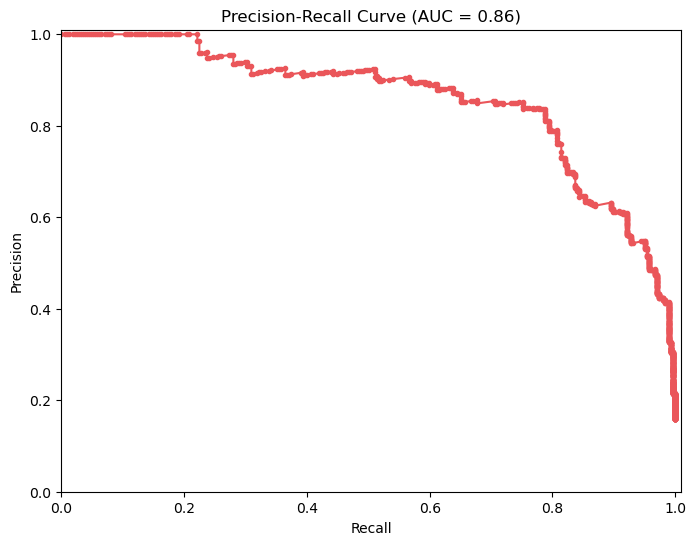

In [11]:
# Make predictions on the held-out grouped test set
y_pred_label = best_model.predict(X_test)
print(classification_report(y_test, y_pred_label))

y_pred = best_model.predict_proba(X_test)[:, 1]
 
# Calculate precision, recall, and thresholds
precision, recall, thresholds = precision_recall_curve(y_test, y_pred)
 
# Calculate the area under the PR curve
auc_score = auc(recall, precision)
 
# Plot the Precision-Recall curve
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, marker='.', label='PR Curve', color='#ea565aff')
plt.xlim(0, 1.01)
plt.ylim(0, 1.01)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'Precision-Recall Curve (AUC = {auc_score:.2f})')
plt.show()
